# Homework 2 (Hard deadline: 17.11.2026 22:00)



- Use the sns Titanic dataset
- Read it first in Pandas DataFrame and then complete the tasks.
- Remember to comment your code, good policy is to have at least a short comment in every code cell.
- Add code cells when necessary.
- Good policy is to do one or few related operations in one code cell (e.g. read csv and check how it looks like in one cell and then e.g. df.info() in another etc.).
- Max points: 18




### Use of AI: can be used, but must be reported.
### AI shall not be used to complete the whole assignment.

In [166]:
# Take necessary libraries in use
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Task 1: Data reading and checking (1 point total)
1. Read the Titanic dataset to a Pandas DataFrame whose name is df.
2. Check that data looks ok.
3. Show number of rows and columns.
4. Show also info about DataFrame.
5. Show key data measures (mean, std, median, ...) for the DataFrame.
6. Check if there are missing values.
7. Answer the questions (see the questions after the coding cells).



In [167]:
# Your code here, add more cells when needed
# Read Titanic dataset
titanic = sns.load_dataset('titanic')
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [168]:
# Number of rows and columns:
print(f"The Titanic dataframe has {titanic.shape[1]} columns and {titanic.shape[0]} rows")
# Show info
titanic.info()

The Titanic dataframe has 15 columns and 891 rows
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [169]:
# Describle
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [170]:
# Check if data is missing
titanic.isna().any()

survived       False
pclass         False
sex            False
age             True
sibsp          False
parch          False
fare           False
embarked        True
class          False
who            False
adult_male     False
deck            True
embark_town     True
alive          False
alone          False
dtype: bool

7. Answer the following questions:
   
    1. Which column has the most missing values?
    - Your answer here: age, embarked, deck, embark_town
    2. Why might missing values be problematic?
    - Your answer here: The missing values are likely due to a lack of human record-keeping, as they could have been recorded but weren't.



## Task 2: GroupBy (1 point each = 3 in total)
1. Calculate the survival rate for each passenger class (pclass). Use GroupBy(). Use 2-decimal precision.
2. Calculate the average age and average fare for each passenger class. Use GroupBy(). Use 2-decimal precision.
3. Answer the questions (see the questions after the code cells).

In [171]:
# Your code here, add more cells when needed
# 1. Calculate the survival rate for each passenger class (pclass). Use GroupBy(). Use 2-decimal precision.

titanic.groupby('pclass')['survived'].mean().round(2)

pclass
1    0.63
2    0.47
3    0.24
Name: survived, dtype: float64

In [172]:
# 2. Calculate the average age and average fare for each passenger class. Use GroupBy(). Use 2-decimal precision.
titanic.groupby('pclass')[['age', 'fare']].mean().round(2)

,age,fare
pclass,,
1,38.23,84.15
2,29.88,20.66
3,25.14,13.68


3. Interprete the tables:
- Which passenger class had the highest survival rate? ==> **Class 1 (the richest group) had the highest survival rate.**
- Which group paid the lowest fares?  ==> **Class 3 (the poorest) paid the lowest fares**

## Task 3: CrossTab (1 point each = 2 points in total)
1. Create a crosstab sex x survived, use .map({0: "No", 1: "Yes"}) to change the column indexes.
2. Create a crosstab sex x survived (change the column indexes) and normalize over each row. Round to 2 decimal precision. Hint: Check the correct parameter and its value from here https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html

In [173]:
# Your code here, add more cells when needed
# 1. Create a crosstab sex x survived, use .map({0: "No", 1: "Yes"}) to change the column indexes.
ct = pd.crosstab(titanic['sex'], titanic['survived'])
ct.columns = ct.columns.map({0: "No", 1: "Yes"})
ct

survived,No,Yes
sex,,
female,81,233
male,468,109


In [174]:
# 2. Create a crosstab sex x survived (change the column indexes) and normalize over each row. Round to 2 decimal precision. 
# Hint: Check the correct parameter and its value from here https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html

ct = pd.crosstab(titanic['sex'], titanic['survived'], normalize=True)
ct.columns = ct.columns.map({0: "No", 1: "Yes"})
ct

survived,No,Yes
sex,,
female,0.090909,0.261504
male,0.525253,0.122334


## Task 4: Pivot tables (1 point each = 4 points in total)



1. Create a pivot table showing:
- rows: passenger class
- columns: sex
- values: fare
- aggregation: mean

In [175]:
# Your code here, add more cells when needed
# 1. Create a pivot table showing:
pt = titanic.pivot_table(index='pclass', columns='sex', values='fare', aggfunc='mean')
pt.style.format({'female': '{:.2f}', 'male': '{:.2f}'})

sex,female,male
pclass,,
1,106.13,67.23
2,21.97,19.74
3,16.12,12.66


2. Create a pivot table showing:

- rows: embark_town
- columns: sex
- values: age
- aggregation: mean

In [176]:
# Your code here, add more cells when needed
# Task 2
pt2 = titanic.pivot_table(index='embark_town', columns='sex', values='age', aggfunc='mean')
pt2.style.format({'female': '{:.2f}', 'male': '{:.2f}'})

sex,female,male
embark_town,,
Cherbourg,28.34,33.00
Queenstown,24.29,30.94
Southampton,27.77,30.29


3. Create a pivot table showing:
- rows: passenger class
- columns: survived
- values: fare
- aggregation: mean

In [177]:
# Your code here, add more cells when needed
# Task 3
pt3 = titanic.pivot_table(index='pclass', columns='survived', values='fare', aggfunc='mean')
pt3.rename(columns={0: 'Died', 1: 'Alive'}, inplace=True)
pt3.style.format({'Died': '{:.2f}', 'Alive': '{:.2f}'})

survived,Died,Alive
pclass,,
1,64.68,95.61
2,19.41,22.06
3,13.67,13.69


4. Which question does the pivot table answer in those three tasks above (complete the questions). For example (these are not the only "right" answers here):
- 1: What is the average fare passangers paid in each passanger class separated by sex. ==> **Yes this question can be answered. We have the clear numbers in task 4.3**
- 2: What is the average age of passangers per each embark town separated by sex. ==> **We can find the answer tn the task 4.2 output**
- 3: What is the average fare survived and not survived passangers paid in each passanger class. ==> **We can find the answer tn the task 4.1 output**


## Task 5: Data scaling (half a point each = 3 points in total)
Machine learning models often perform better when variables are on similar scales.

1. Select variables age and fare from the DataFrame df.
2. Remove rows with missing values in these variables.
3. Calculate their mean() and std() before scaling and print them out. Use 2 decimal precision.
4. Scale both variables using StandardScaler().
5. Calculate their mean() and std() after scaling and print them out.
6. Explain why the mean and std are what they are after scaling.






In [178]:
# Your code here, add more cells when needed
# 1. Select and and fare only
ds = titanic[['age', 'fare']]
ds

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


In [179]:
# 2. Remove missing values
ds.dropna(inplace=True)
ds

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


In [180]:
# Calculate mean and std before scaling, using 2 digits of decimal precision
print("Before scaling:")
print("\r\nMean")
print(ds.mean().round(2))
print("\r\nStd")
print(ds.std().round(2))

Before scaling:

Mean
age     29.70
fare    34.69
dtype: float64

Std
age     14.53
fare    52.92
dtype: float64


In [181]:
# 4. Scaling both variables, using standard scale
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler();
scaled = scaler.fit_transform(ds)
new_ds = pd.DataFrame(scaled, columns=['age', 'fare'])
new_ds

,age,fare
0,-0.530377,-0.518978
1,0.571831,0.691897
2,-0.254825,-0.506214
3,0.365167,0.348049
4,0.365167,-0.503850
...,...,...
709,0.640719,-0.105320
710,-0.185937,-0.410245
711,-0.737041,-0.088774
712,-0.254825,-0.088774


In [182]:
# 5. Calculate their mean() and std() after scaling and print them out.
print("After scaling:")
print("\r\nMean")
print(new_ds.mean().round(2))
print("\r\nStd")
print(new_ds.std().round(2))

After scaling:

Mean
age     0.0
fare   -0.0
dtype: float64

Std
age     1.0
fare    1.0
dtype: float64


Task 5.6:
Your answer here

### 6. Explain why the mean and std are what they are after scaling.

#### Mean:

The mean value should be 0 (zero) because the mean calculation sums all $(x - \text{mean}) / \text{std}$. Therefore, the sum of $(x - \text{mean})$ must be 0.

#### Std:
After applying the standard scaling, the Standard Deviation (std) should be 1.

## Task 6: Linear regression (1 point each = 5 points in total)

1. Use age as the independent variable X and fare as the dependent variable y and fit a linear regression model.
2. Print out the slope and intercept, use 2 decimal precision.
3. Plot a scatter plot with a regression line.
4. Print out the R^2 (R squared) value. Hint: score(X,y). Use 5 decimal precision.
5. Based on the scatterplot and the R^2 value, do you think there is a linear relationship between the age and fare? Why/why not? Also explain, what is the R^2 value.

In [183]:
# Your code here, add more cells when needed
# 1. Train the linear regression mode
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(new_ds[['age']], new_ds['fare'])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.1]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-8.218e-17
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [184]:
# 2. Print the coefficient and slope.
slope = model.coef_
intercept = model.intercept_
print(f"Slope: {slope}")
print(f"Intercept: {intercept}")

Slope: [0.09606669]
Intercept: -8.217583234184855e-17


Text(0, 0.5, 'fare')

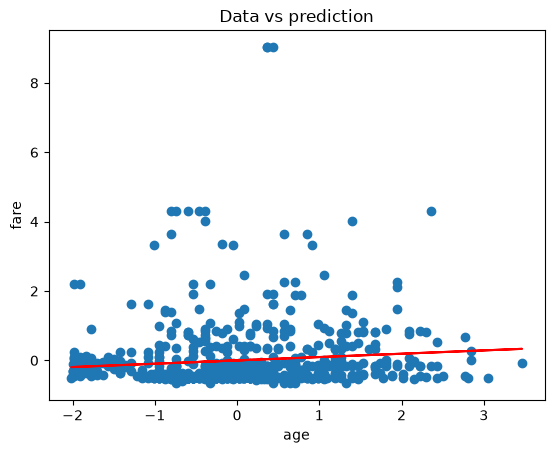

In [185]:
# 3. Plot the scatter plot with the regression line
X = new_ds[['age']]
y = new_ds['fare']
plt.scatter(X, y) 
plt.plot(X, model.predict(X), color='red', label='Predict')
plt.title('Data vs prediction')
plt.xlabel('age')
plt.ylabel('fare')

In [186]:
# 4. Print out the R^2 (R squared) value. Hint: score(X,y). Use 5 decimal precision.
r2 = model.score(new_ds[['age']], new_ds['fare'])
print("R^2:", round(r2, 5))

R^2: 0.00923


Task 6.5:

Based on the scatterplot, age and fare do not show a clear linear relationship: as age changes, fare appears scattered rather than following a trend, and the regression line is nearly flat (slope close to 0). 

The R^2 value is very close to 0, which means age explains almost none of the variance in fare. 

Therefore, there is essentially no linear relationship between age and fare.


## Task: AI statement (mandatory, missing AI statement (if AI used) is considered fraud)
- I used AI to correct my grammar errors.
- I used AI to explain the mean and standard deviation after standard scaling.
- In some cases, I used AI to correct my programming syntax.
- I did not use AI to help me write code.


## Task: Self assessment (mandatory, missing self assessment causes -1 point)
- How many points would you give yourself? ANSWER HERE: 13
- You get a point if you have completed the task according to instructions.
- How many tasks you did not complete? ANSWER HERE: 0

## Homework return (mandatory)
- File > Save and Export Notebook As > HTML
- Then take a look the produced HTML that it looks ok and readable (= it looks like this Jupyter notebook looks, so no html source code etc. shall be visible)
- Return to Itslearning, only the html document is returned, *not the .ipynb